# Lab 3 — Testing claims and comparing groups

**Lecture connections: weeks 5–7. Time: 60 minutes.**

Choose a test from the question and sampling design, connect its statistic to an effect estimate,
and explain the errors a decision rule can make.

| Minutes | Task |
|---|---|
| 0–5 | State the question, parameter and observational unit |
| 5–17 | Test a process mean and connect the interval |
| 17–25 | Investigate Type I error and power |
| 25–35 | Compare two independent groups |
| 35–43 | Analyse paired observations |
| 43–55 | Test categorical association |
| 55–60 | Report a finding |

Run the supplied code in order. Make a prediction and interpret the output; programming is a tool
for investigating the statistical argument. Optional investigations follow the exit task.

## 1. A test starts with a question (0–5 minutes)

**Weeks 5–7.** Before examining a p-value, state the population parameter, null value,
alternative, significance level and observational unit.

| Question | Unit/design | Procedure |
|---|---|---|
| Has a process mean changed from 12? | Independent readings in one sample | One-sample mean test |
| Do two age groups have different mean memory scores? | Different participants | Welch two-sample t-test |
| Is mean TV time different from mean radio time? | Both measurements from each person | Paired t-test on differences |
| Is subscription associated with contact category? | Counts in a two-way table | Chi-square independence test |

A p-value is a probability, under the null model, of a result at least as extreme as the one observed.
It is not the probability that the null is true. Choose a one-sided alternative from the scientific
question before seeing the direction of the sample result.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Open the notebook from its own folder or from the repository root.
DATA = Path('.') if Path('quality-control.csv').exists() else Path('Lab3')
if not (DATA / 'quality-control.csv').exists():
    raise FileNotFoundError('Open this notebook from Lab3 or the repository root.')
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_columns', 12)

## 2. Monitor a process mean (5–17 minutes)

**Week 5: known SD, estimated SD, confidence intervals and tests.**
Quality Associates monitors a process with target mean 12 units. Four hourly samples each contain
30 readings. For this calculation, treat the historical SD of 0.21 as a fixed, known process SD.
Assume independent readings and a normal sampling distribution for the mean.

Test $H_0:\mu=12$ against $H_A:\mu\ne12$ separately for each sample at $\alpha=0.01$.
The statistic is $z=(\bar x-12)/(0.21/\sqrt{30})$.

**Predict:** Which sample means would be far enough from 12 to trigger an alert?

,mean,sample SD,z,p-value,99% CI lower,99% CI upper,alert at 1%
Sample 1,11.95867,0.22036,-1.07806,0.28101,11.85991,12.05743,False
Sample 2,12.02867,0.22036,0.74768,0.45465,11.92991,12.12743,False
Sample 3,11.88900,0.20717,-2.89510,0.00379,11.79024,11.98776,True
Sample 4,12.08133,0.20611,2.12134,0.03389,11.98257,12.18009,False


Limits for a new 30-reading sample mean: [11.9012 12.0988]


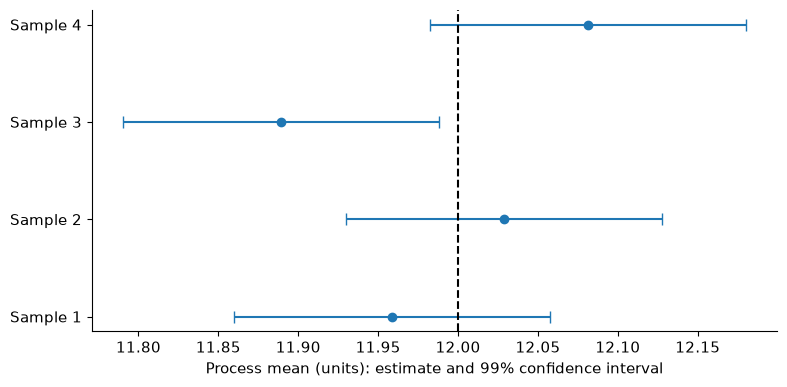

In [2]:
quality = pd.read_csv(DATA / 'quality-control.csv')
mu0, known_sigma, alpha = 12.0, 0.21, 0.01
n = quality.count()
means = quality.mean()
se_known = known_sigma / np.sqrt(n)
z = (means - mu0) / se_known
p_values = 2 * stats.norm.sf(np.abs(z))
critical = stats.norm.ppf(1-alpha/2)
quality_result = pd.DataFrame({'mean': means, 'sample SD': quality.std(ddof=1),
                               'z': z, 'p-value': p_values,
                               '99% CI lower': means-critical*se_known,
                               '99% CI upper': means+critical*se_known,
                               'alert at 1%': p_values < alpha})
display(quality_result.round(5))
control_limits = (mu0-critical*known_sigma/np.sqrt(30), mu0+critical*known_sigma/np.sqrt(30))
print('Limits for a new 30-reading sample mean:', np.round(control_limits, 4))

plt.errorbar(means, np.arange(4), xerr=critical*se_known, fmt='o', capsize=4)
plt.yticks(np.arange(4), quality.columns)
plt.axvline(mu0, color='black', linestyle='--')
plt.xlabel('Process mean (units): estimate and 99% confidence interval')
plt.tight_layout()
plt.show()

**Discuss:** Which interval excludes 12? Why are the control limits centred at the target while
each confidence interval is centred at a sample mean?

If the process SD must be estimated from a current sample, use its sample SD and a t reference
distribution. The historical value 0.21 is itself an estimate in practice; the known-SD analysis
treats it as fixed in this calculation.

In [3]:
# Compare the estimated-SD analysis with the known-SD result, without changing the data.
t_result = stats.ttest_1samp(quality.to_numpy(), popmean=mu0, axis=0)
display(pd.DataFrame({'t': t_result.statistic, 'two-sided p-value': t_result.pvalue}, index=quality.columns))

,t,two-sided p-value
Sample 1,-1.027392,0.312730
Sample 2,0.712546,0.481821
Sample 3,-2.934644,0.006469
Sample 4,2.161386,0.039059


<details>
<summary>Check your reasoning</summary>

At 1%, Sample 3 triggers an alert and its 99% interval excludes 12. The control limits are
approximately 11.9012 and 12.0988 units. These are limits for a sample mean under the null,
whereas a confidence interval is constructed around the observed mean to estimate the unknown target.
Non-rejection means insufficient evidence of a change under this rule; it does not establish exact equality.

</details>

**Your response:** Report Sample 3's estimated change from 12, its p-value, the decision and the SD assumption.

## 3. Errors and power (17–25 minutes)

**Week 6: evaluate a decision rule under different true means.**
For approval times, test $H_0:\mu\geq5$ against $H_A:\mu<5$ days. Assume known $\sigma=1.5$
days and a normal sampling mean. Reject when $\bar X<c$, where
$c=5+z_\alpha\sigma/\sqrt n$.

**Predict:** At the same $\alpha$, does increasing n improve the chance of detecting a true mean
of 4.8 days? What happens if you reduce $\alpha$ while keeping n fixed?

,alpha,n,cutoff (days),beta at 4.8,power at 4.8,simulated Type I rate,simulated power
0,0.05,36,4.5888,0.8009,0.1991,0.0495,0.1984
1,0.01,36,4.4184,0.9365,0.0635,0.0107,0.0598
2,0.05,144,4.7944,0.5179,0.4821,0.0526,0.4813


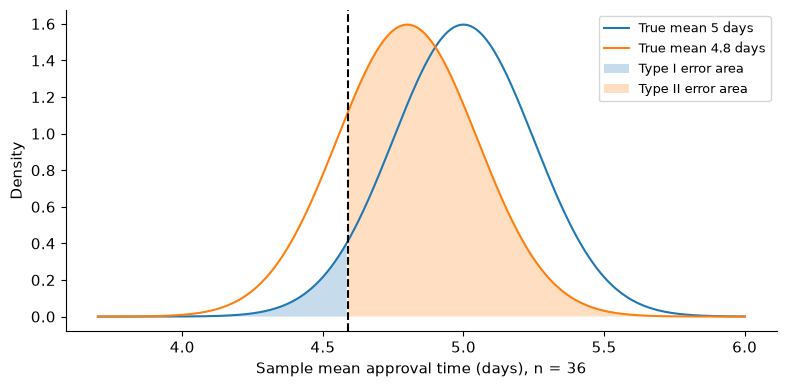

In [4]:
mu0, alternative_mu, sigma = 5.0, 4.8, 1.5
rng = np.random.default_rng(306)
power_rows = []
for alpha, n in [(0.05, 36), (0.01, 36), (0.05, 144)]:
    se = sigma/np.sqrt(n)
    cutoff = mu0 + stats.norm.ppf(alpha)*se
    # Both probabilities use exactly the same rejection rule.
    power = stats.norm.cdf(cutoff, loc=alternative_mu, scale=se)
    null_means = rng.normal(mu0, se, size=20000)
    alternative_means = rng.normal(alternative_mu, se, size=20000)
    power_rows.append([alpha, n, cutoff, 1-power, power,
                       (null_means < cutoff).mean(), (alternative_means < cutoff).mean()])
display(pd.DataFrame(power_rows, columns=['alpha', 'n', 'cutoff (days)', 'beta at 4.8',
                                          'power at 4.8', 'simulated Type I rate', 'simulated power']).round(4))

se = sigma/np.sqrt(36)
cutoff = mu0 + stats.norm.ppf(0.05)*se
x = np.linspace(3.7, 6.0, 500)
null_density = stats.norm.pdf(x, mu0, se)
alternative_density = stats.norm.pdf(x, alternative_mu, se)
plt.plot(x, null_density, label='True mean 5 days')
plt.plot(x, alternative_density, label='True mean 4.8 days')
plt.fill_between(x, null_density, where=x < cutoff, alpha=0.25, label='Type I error area')
plt.fill_between(x, alternative_density, where=x >= cutoff, alpha=0.25, label='Type II error area')
plt.axvline(cutoff, linestyle='--', color='black')
plt.xlabel('Sample mean approval time (days), n = 36')
plt.ylabel('Density')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

<details>
<summary>Check your reasoning</summary>

At n = 36 and alpha = 0.05, the cutoff is about 4.589 days and power at 4.8 is about 0.199.
Lowering alpha lowers the false-alarm rate but also lowers power for this fixed sample size and alternative.
Increasing n narrows the sampling distributions and increases power. Beta must refer to a specified
alternative; it is not calculated from the observed p-value.

</details>

## 4. Independent groups: spatial memory (25–35 minutes)

**Week 6: estimate a difference in means.** Return to the spatial-memory participants from Lab 1.
Compare mean city-block score in the Elderly and Young groups. Define the effect as Elderly minus
Young; higher scores mean greater total placement error.

Test $H_0:\mu_E-\mu_Y=0$ against a two-sided alternative. Welch's procedure estimates the
two variances separately. Use the study design to assess independence, and inspect each small
sample for skewness and extreme values.

,count,mean,std
Age group,,,
Elderly,14,27.714,9.667
Young,13,14.462,9.921


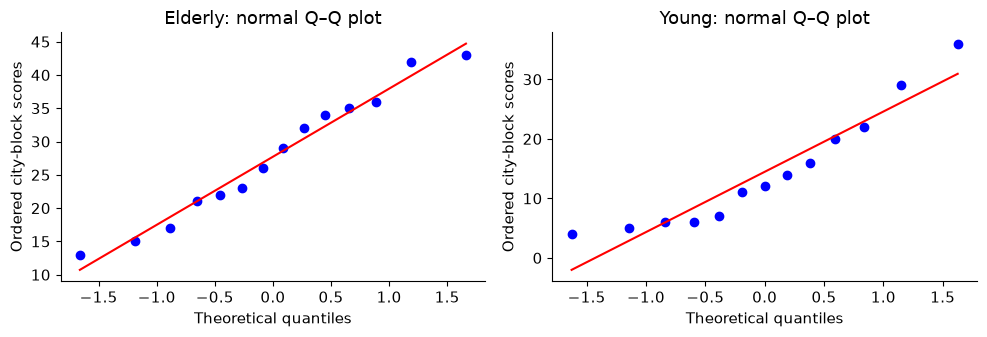

Elderly − Young: 13.253 blocks; 95% CI [ 5.475 21.031]
Welch t=3.511, df=24.74, p=0.001736


In [5]:
spatial = pd.read_csv(DATA / 'spatial-memory.csv')
elderly = spatial.loc[spatial['Age group'].eq('Elderly'), 'City block score'].to_numpy()
young = spatial.loc[spatial['Age group'].eq('Young'), 'City block score'].to_numpy()
display(spatial.groupby('Age group')['City block score'].agg(['count', 'mean', 'std']).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, values, name in zip(axes, [elderly, young], ['Elderly', 'Young']):
    stats.probplot(values, dist='norm', plot=ax)
    ax.set_title(f'{name}: normal Q–Q plot')
    ax.set_ylabel('Ordered city-block scores')
plt.tight_layout()
plt.show()

mean_difference = elderly.mean() - young.mean()
v_e = elderly.var(ddof=1)/len(elderly)
v_y = young.var(ddof=1)/len(young)
se_difference = np.sqrt(v_e+v_y)
welch_df = (v_e+v_y)**2 / (v_e**2/(len(elderly)-1) + v_y**2/(len(young)-1))
welch = stats.ttest_ind(elderly, young, equal_var=False)
welch_ci = mean_difference + np.array([-1, 1])*stats.t.ppf(0.975, welch_df)*se_difference
print(f'Elderly − Young: {mean_difference:.3f} blocks; 95% CI {welch_ci.round(3)}')
print(f'Welch t={welch.statistic:.3f}, df={welch_df:.2f}, p={welch.pvalue:.4g}')

**Discuss:** Interpret the sign and units of the difference. Do the data support a precise estimate?
What would a confidence interval containing zero mean? A Q–Q plot checks departures from a normal
shape; it cannot verify independent sampling. Welch avoids an equal-variance assumption, but small
samples with strong skewness or influential observations still need care.

## 5. Paired data: television and radio (35–43 minutes)

**Week 6: each difference belongs to one participant.** Fifteen people report weekly television
and radio hours. Define $D=TV-Radio$, and test $H_0:\mu_D=0$ against $H_A:\mu_D\ne0$.
Inspect the differences when assessing the shape assumption for a paired t-test.

**Predict:** Would sorting each column separately preserve the study's pairs?

Mean TV − radio = -1.200 hours/week; 95% CI [-2.292 -0.108]
Paired t=-2.358, df=14, p=0.03347


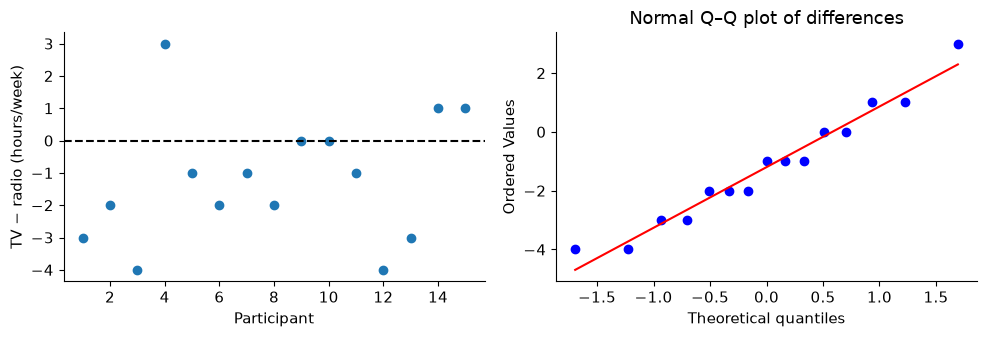

In [6]:
media = pd.read_csv(DATA / 'tv-radio.csv')
difference = media['Television'] - media['Radio']
n = len(difference)
paired = stats.ttest_rel(media['Television'], media['Radio'])
se_difference = difference.std(ddof=1)/np.sqrt(n)
paired_ci = difference.mean() + np.array([-1, 1])*stats.t.ppf(0.975, n-1)*se_difference
print(f'Mean TV − radio = {difference.mean():.3f} hours/week; 95% CI {paired_ci.round(3)}')
print(f'Paired t={paired.statistic:.3f}, df={n-1}, p={paired.pvalue:.4g}')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(np.arange(1, n+1), difference)
axes[0].axhline(0, color='black', linestyle='--')
axes[0].set(xlabel='Participant', ylabel='TV − radio (hours/week)')
stats.probplot(difference, dist='norm', plot=axes[1])
axes[1].set_title('Normal Q–Q plot of differences')
plt.tight_layout()
plt.show()

<details>
<summary>Check your reasoning</summary>

The paired t-test is a one-sample t-test on the 15 within-person differences.
Sorting the columns separately breaks those pairs. It leaves the two marginal means, and thus
the mean difference, unchanged but changes the SD of the differences and its SE.
The comparison concerns weekly time in these two activities; it is not a treatment effect.

</details>

**Your response:** Explain why independent and paired t-tests require different standard errors.

## 6. Categorical association (43–55 minutes)

**Week 7: compare observed counts with counts expected under independence.**
For the UCI bank records, test independence of contact category and subscription.
Under $H_0$, each contact group has the same subscription probability.

$$E_{ij}=\frac{(\text{row total})_i(\text{column total})_j}{N},\qquad
X^2=\sum_{ij}\frac{(O_{ij}-E_{ij})^2}{E_{ij}}.$$

**Predict:** Calculate the expected count of cellular subscriptions from the margins before running
the test. Which denominator belongs in a within-contact subscription rate?

y,no,yes
contact,,
cellular,24916,4369
telephone,2516,390
unknown,12490,530


,records,subscription rate
contact,,
cellular,29285,0.149189
telephone,2906,0.134205
unknown,13020,0.040707


y,no,yes
contact,,
cellular,25859.10,3425.90
telephone,2566.04,339.96
unknown,11496.86,1523.14


y,no,yes
contact,,
cellular,34.40,259.62
telephone,0.98,7.37
unknown,85.79,647.56


χ²=1035.714, df=2, p=1.25e-225, minimum expected count=339.96, V=0.151


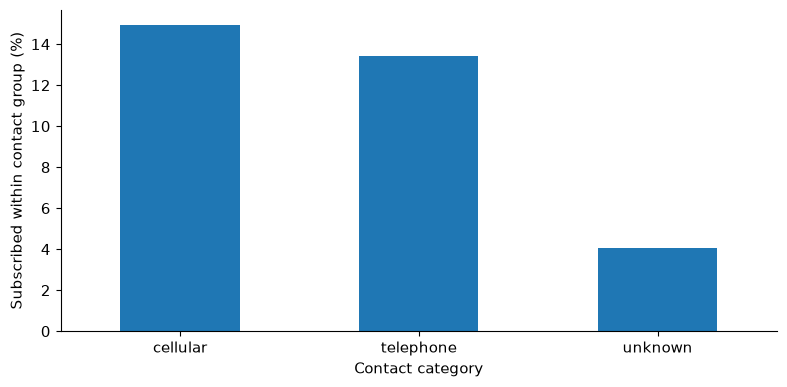

In [7]:
bank = pd.read_csv(DATA / 'bank-marketing.csv')
observed = pd.crosstab(bank['contact'], bank['y']).reindex(index=['cellular', 'telephone', 'unknown'], columns=['no', 'yes'])
display(observed)
rates = observed['yes']/observed.sum(axis=1)
display(pd.DataFrame({'records': observed.sum(axis=1), 'subscription rate': rates}))

# Expected counts follow from the fitted margins, with no continuity correction.
chi2, chi_p, chi_df, expected = stats.chi2_contingency(observed, correction=False)
contributions = (observed.to_numpy()-expected)**2/expected
display(pd.DataFrame(expected, index=observed.index, columns=observed.columns).round(2))
display(pd.DataFrame(contributions, index=observed.index, columns=observed.columns).round(2))
cramers_v = np.sqrt(chi2/(observed.to_numpy().sum()*min(observed.shape[0]-1, observed.shape[1]-1)))
print(f'χ²={chi2:.3f}, df={chi_df}, p={chi_p:.3g}, minimum expected count={expected.min():.2f}, V={cramers_v:.3f}')

rates.mul(100).plot.bar(rot=0)
plt.ylabel('Subscribed within contact group (%)')
plt.xlabel('Contact category')
plt.tight_layout()
plt.show()

**Discuss:** Which cells contribute most to the statistic? Distinguish evidence of association from
its size, using rates and Cramér's V. All expected counts exceed five here, satisfying a useful
classroom check for the chi-square approximation.

Inference assumes independent records under a defensible sampling model. This public campaign
file has no client identifier to check repeated-client dependence, and it is not a random sample
of all customers. The observed rates describe the file; causal comparisons require a suitable design.

<details>
<summary>Check your reasoning</summary>

The expected cellular subscription count is its row total multiplied by 5,289/45,211.
Degrees of freedom are (3−1)(2−1) = 2. The unknown-contact group has a much lower observed
subscription rate and substantial contributions to the statistic. The very small p-value is
evidence against independence under the stated model; it does not show that changing a contact method causes subscription.

</details>

## 7. Exit task (55–60 minutes)

**Your response:** Choose one comparison. State the question and design, give an effect estimate
with units or rates, report the interval/test evidence, and identify the population claim the design supports.
Then state which statistical error is controlled by alpha.

---

## Optional investigation A — One and two proportions

**Weeks 5–7.** Test a stipulated default-count example: 18 defaults in 200 independent loans,
against a benchmark probability of 0.05, with a prespecified upper-tailed alternative.
Then compare cellular and telephone subscription proportions. The equality test pools the rates;
an interval for their difference estimates each rate separately.

In [8]:
successes, n, p0 = 18, 200, 0.05
z_one = (successes/n-p0)/np.sqrt(p0*(1-p0)/n)
exact = stats.binomtest(successes, n, p=p0, alternative='greater')
print(f'One-proportion normal p={stats.norm.sf(z_one):.4g}; exact binomial p={exact.pvalue:.4g}')

two = observed.loc[['cellular', 'telephone']]
successes = two['yes'].to_numpy()
sizes = two.sum(axis=1).to_numpy()
proportions = successes/sizes
pooled = successes.sum()/sizes.sum()
se_null = np.sqrt(pooled*(1-pooled)*np.sum(1/sizes))
z_two = (proportions[0]-proportions[1])/se_null
se_interval = np.sqrt(np.sum(proportions*(1-proportions)/sizes))
diff = proportions[0]-proportions[1]
diff_ci = diff + np.array([-1, 1])*stats.norm.ppf(0.975)*se_interval
chi2_two = stats.chi2_contingency(two, correction=False)
print(f'Cellular − telephone: {100*diff:.3f} percentage points; 95% CI {100*diff_ci}')
print(f'z={z_two:.3f}; two-sided p={2*stats.norm.sf(abs(z_two)):.4g}')
print(f'z²={z_two**2:.6f}; uncorrected 2×2 χ²={chi2_two.statistic:.6f}')
print(f'Risk ratio={proportions[0]/proportions[1]:.3f}; odds ratio={(proportions[0]/(1-proportions[0]))/(proportions[1]/(1-proportions[1])):.3f}')

One-proportion normal p=0.004722; exact binomial p=0.01209
Cellular − telephone: 1.498 percentage points; 95% CI [0.19360033 2.80318201]
z=2.171; two-sided p=0.02996
z²=4.711428; uncorrected 2×2 χ²=4.711428
Risk ratio=1.112; odds ratio=1.131


## Optional investigation B — Goodness of fit, homogeneity and chi-square tails

**Week 7.** In an illustrative sample, 140, 90 and 70 customers prefer savings, current and
investment accounts. Test the specified probabilities 0.5, 0.3 and 0.2.
Goodness of fit compares one categorical variable with a specified distribution.

Goodness of fit: χ²=2.3333, df=2, p=0.3114


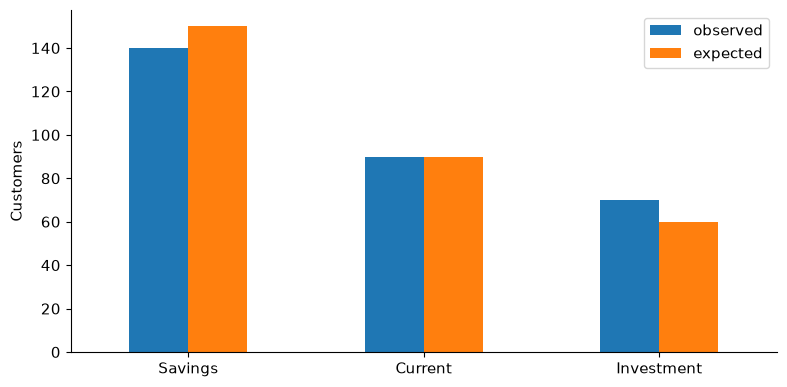

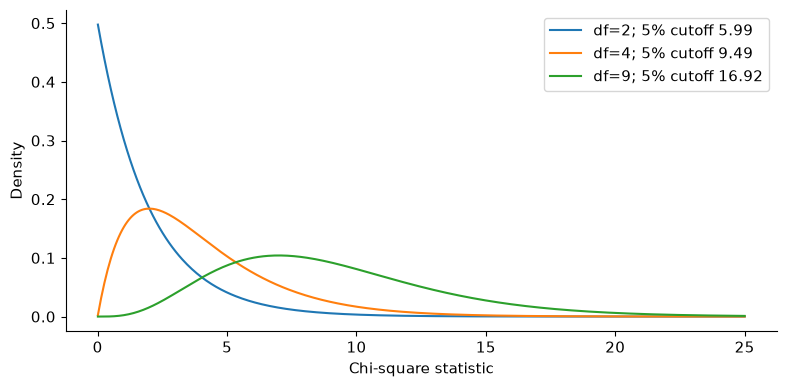

,Savings,Current,Investment
North,50,30,20
Central,35,45,20
South,40,25,35


Homogeneity: χ²=15.300, df=4, p=0.004118


In [9]:
account_counts = np.array([140, 90, 70])
expected_accounts = account_counts.sum()*np.array([0.5, 0.3, 0.2])
gof = stats.chisquare(account_counts, f_exp=expected_accounts)
print(f'Goodness of fit: χ²={gof.statistic:.4f}, df=2, p={gof.pvalue:.4g}')
pd.DataFrame({'observed': account_counts, 'expected': expected_accounts},
             index=['Savings', 'Current', 'Investment']).plot.bar(rot=0)
plt.ylabel('Customers')
plt.tight_layout()
plt.show()

x = np.linspace(0.01, 25, 400)
for df in [2, 4, 9]:
    plt.plot(x, stats.chi2.pdf(x, df), label=f'df={df}; 5% cutoff {stats.chi2.isf(0.05, df):.2f}')
plt.xlabel('Chi-square statistic')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

# Separate independent samples of 100 customers per region: an illustrative homogeneity design.
regions = pd.DataFrame([[50, 30, 20], [35, 45, 20], [40, 25, 35]],
                       index=['North', 'Central', 'South'], columns=['Savings', 'Current', 'Investment'])
homogeneity = stats.chi2_contingency(regions, correction=False)
display(regions)
print(f'Homogeneity: χ²={homogeneity.statistic:.3f}, df={homogeneity.dof}, p={homogeneity.pvalue:.4g}')

<details>
<summary>Check your reasoning</summary>

The account-preference statistic is 2.3333 with p about 0.3114, so this sample does not reject
the specified distribution at 5%. Large discrepancies contribute to the upper chi-square tail.
Homogeneity asks whether category distributions match across separately sampled populations;
independence asks whether two variables are associated in one population. The Pearson calculation
is the same for the same table, but the sampling design determines the interpretation.

</details>

## Optional investigation C — Subscriber survey

**Week 7.** The Young Professional magazine case contains 410 subscriber responses.
Test whether the recorded gender category and planned real-estate purchase are associated.
State the hypotheses before looking at the output, then report rates as well as the test.

In [10]:
professional = pd.read_csv(DATA / 'professional-survey.csv')
survey_table = pd.crosstab(professional['Gender'], professional['Real Estate Purchases?'])
survey_test = stats.chi2_contingency(survey_table, correction=False)
display(survey_table)
display(survey_table.div(survey_table.sum(axis=1), axis=0).round(3))
print(f'Pearson χ²={survey_test.statistic:.3f}, df={survey_test.dof}, p={survey_test.pvalue:.4g}')
print('Smallest expected count:', survey_test.expected_freq.min())

Real Estate Purchases?,No,Yes
Gender,,
Female,97,84
Male,132,97


Real Estate Purchases?,No,Yes
Gender,,
Female,0.536,0.464
Male,0.576,0.424


Pearson χ²=0.673, df=1, p=0.4121
Smallest expected count: 79.90487804878049


Treat the recorded responses as a sample for this inference exercise. Check subscriber selection
and response mechanisms before extending the result to a magazine audience. Choosing many pairs
of variables after seeing their p-values creates a multiple-testing problem.

## Optional investigation D — Pairing, equal variances and repeated alerts

**Week 6.** Compare the paired SE with an analysis treating measurements as independent.
For the memory data, compare Welch's result with the pooled-variance t-test: the latter requires a
common population variance. A preliminary variance test is not required to use Welch.

In [11]:
paired_se = difference.std(ddof=1)/np.sqrt(len(difference))
unpaired_se = np.sqrt((media['Television'].var(ddof=1)+media['Radio'].var(ddof=1))/len(media))
rng = np.random.default_rng(307)
broken_difference = media['Television'].to_numpy() - rng.permutation(media['Radio'].to_numpy())
display(pd.DataFrame({'mean difference': [difference.mean(), broken_difference.mean()],
                      'SE': [paired_se, broken_difference.std(ddof=1)/np.sqrt(len(media))]},
                     index=['correct pairs', 'shuffled radio partners']))
print('SE treating columns as independent:', unpaired_se)
pooled_t = stats.ttest_ind(elderly, young, equal_var=True)
print(f'Pooled t={pooled_t.statistic:.3f}, p={pooled_t.pvalue:.4g}; Welch p={welch.pvalue:.4g}')
print('Chance of at least one false alert in 100 independent null tests at 1%:', 1-(1-0.01)**100)

,mean difference,SE
correct pairs,-1.2,0.508967
shuffled radio partners,-1.2,1.974118


SE treating columns as independent: 1.9789367034320415
Pooled t=3.515, p=0.001702; Welch p=0.001736
Chance of at least one false alert in 100 independent null tests at 1%: 0.6339676587267709


## Data guide

| File | Records and variables |
|---|---|
| `quality-control.csv` | 30 rows and four hourly samples of process readings, in unspecified process units |
| `spatial-memory.csv` | 27 participants; exact placements, city-block distances and study time in seconds, as in Lab 1 |
| `tv-radio.csv` | 15 participants; `Individual` identifies the pair, and TV/radio measurements are hours per week |
| `professional-survey.csv` | 410 subscriber responses; gender and purchase categories, age, investment/income dollars, transaction counts and household indicators |
| `bank-marketing.csv` | All 45,211 campaign records; `contact` is the last contact category and `y` is subscription |

For the first four datasets, use the sampling assumptions stated in each exercise. Distinguish
a finding about the recorded observations from a claim about a wider population.
Bank data: Moro, S., Rita, P. & Cortez, P. (2014),
[UCI Bank Marketing](https://doi.org/10.24432/C5K306), CC BY 4.0; the two listed columns are selected
from all 45,211 rows of `bank-full.csv`, including the `unknown` contact category.